# Weighted tails and whole-path risk

Family 27. Losses are adverse when positive. ES integrates exactly the worst tail mass, including a fractional atom at VaR. Path breaches refer only to supplied observation times.

In [1]:
from pathlib import Path
import sys
root = Path.cwd()
if not (root / 'convexity').exists():
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({'figure.figsize': (9, 3.5), 'figure.dpi': 110,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .2})
print('Interpreter:', sys.executable)

Interpreter: /home/ethan/miniconda3/envs/quant/bin/python


## Public workflow

The executable example uses only supplied or generated inputs.

In [2]:
"""Family 27: weighted tail risk, Euler allocation and whole-path breaches."""
import numpy as np
from convexity.math import risk, simulation

losses = np.array([-3., 1., 7., 9.])
weights = [.3, .4, .2, .1]
print('Weighted VaR/ES:', risk.value_at_risk(losses, .5, weights=weights),
      risk.expected_shortfall(losses, .5, weights=weights))
contributions = risk.es_contributions([2., -1.], [[1, 0], [0, 2], [3, 1]], .5)
print('ES components:', contributions.component, 'total:', contributions.value)
paths = simulation.PathScenarios([0., 1., 2.], [[100., 110., 95.], [100., 90., 120.]], [.7, .3])
print('Maximum drawdowns:', risk.maximum_drawdown(paths.values))
print('Grid breach probability:', risk.breach_probability(paths, 92.))
print('Stress margin:', risk.scenario_margin(risk.stress(losses, scale=1.5), addon=2.))


Weighted VaR/ES: 1.0 5.0
ES components: [ 4.66666667 -0.66666667] total: 3.9999999999999996
Maximum drawdowns: [0.13636364 0.1       ]
Grid breach probability: 0.3
Stress margin: 15.5


## How atoms change VaR and ES

A finite law has stepwise VaR. ES averages exactly the remaining tail mass and stays continuous in the confidence level below one. The two paths have different maximum drawdowns despite ending above their interim lows.

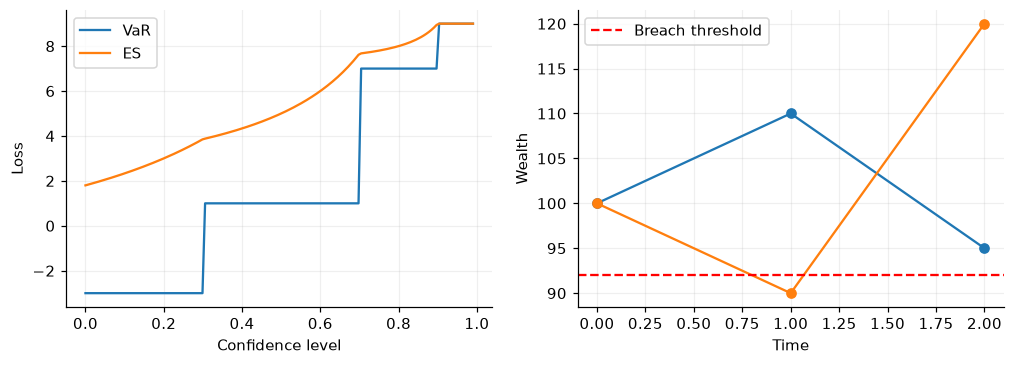

In [3]:
levels = np.linspace(0, .99, 150)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(levels, [risk.value_at_risk(losses, a, weights=weights) for a in levels], label='VaR')
axes[0].plot(levels, [risk.expected_shortfall(losses, a, weights=weights) for a in levels], label='ES')
axes[0].set(xlabel='Confidence level', ylabel='Loss'); axes[0].legend()
axes[1].plot(paths.times, paths.values.T, marker='o')
axes[1].axhline(92., color='red', linestyle='--', label='Breach threshold')
axes[1].set(xlabel='Time', ylabel='Wealth'); axes[1].legend(); plt.show()

## Scope of this evidence

These experiments illustrate the declared finite catalog, not live trading performance. See the [contracts and limitations](../docs/decision_mathematics.md) and `tests/math/decisions/` for mathematical acceptance checks.